# GSM-Symbolic: reproducing the paper at toy scale

**Paper:** Mirzadeh, Alizadeh, Shahrokhi, Tuzel, Bengio, Farajtabar. *GSM-Symbolic: Understanding the Limitations of Mathematical Reasoning in Large Language Models.* **ICLR 2025.** ([arXiv 2410.05229](https://arxiv.org/abs/2410.05229) · [templates repo](https://github.com/apple/ml-gsm-symbolic))

## What the paper contributes
1. **A symbolic benchmark generator.** GSM8K questions are rewritten as *templates*: names and numbers become variables with sampling domains, plus *conditions* that keep each instance valid (e.g. the answer must be an integer). One template gives arbitrarily many fresh, contamination-free variants with a known answer.
2. **Evaluation as a distribution, not a single number.** Sampling 50 datasets (one instance per template each) shows that accuracy **varies a lot across datasets**, and is usually **below** the accuracy on the original GSM8K questions.
3. **Names versus numbers.** Changing only the *names* hurts little. Changing the *numbers* hurts more. That would not happen if the model reasoned instead of pattern-matching.
4. **Difficulty scaling.** GSM-Symbolic-P1 and P2 add 1 or 2 extra clauses. Accuracy drops and variance grows as clauses are added.
5. **GSM-NoOp.** Add one sentence that *seems* relevant but changes nothing ("five of them were a bit smaller than average"). Accuracy drops by up to 65%, because models turn every number they see into an operation.

## What this notebook implements
Apple released the **templates** but **not the generator** (their README says the parser "is not yet published"). This notebook builds it:

| Part | Section |
|---|---|
| Template parser and sampler for Apple's annotation language, checked against all 250 released templates | §2–3 |
| Perturbation modes: `original`, `names`, `numbers`, `both`; plus P1/P2 difficulty levels | §3–4 |
| A GSM-NoOp distractor generator (NoOp templates were not released, so we write our own) | §5 |
| 8-shot chain-of-thought evaluation of small open models (Qwen2.5) | §6–7 |
| The paper's 4 experiments as toy-scale plots | §8 |
| **Statistical sanity checks** in the spirit of the 2026 critique *"The Importance of Being Statistically Earnest"* | §9 |

> Runs on a free Colab T4 in about 20–30 min with `QUICK = True`. Results are cached, so re-running the plots is instant.

## 1. Setup and configuration

In [1]:
# Colab already has most of these; uncomment if needed
# !pip install -q transformers accelerate scipy pandas matplotlib tqdm

In [2]:
import ast, hashlib, io, json, math, os, random, re, zipfile, urllib.request
from collections import Counter
from fractions import Fraction
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ---------------- configuration ----------------
QUICK = False                     # False = closer to paper scale (slower)
MODELS = ["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"]
N_TEMPLATES = 20 if QUICK else 60  # templates per experiment (paper: 100)
N_DATASETS = 8 if QUICK else 25    # instances per template = number of datasets (paper: 50)
BATCH_SIZE = 16
MAX_NEW_TOKENS = 320
SEED = 0

# Smoke-test mode, used only to check that the notebook runs end-to-end on a CPU
if os.environ.get("GSM_SMOKE"):
    MODELS, N_TEMPLATES, N_DATASETS, BATCH_SIZE, MAX_NEW_TOKENS = (
        ["Qwen/Qwen2.5-0.5B-Instruct"], 3, 2, 8, 48)

DATA_DIR = Path("gsm_templates")
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

## 2. Download Apple's released templates
Each template is a JSON file. `question_annotated` holds the template; `question` / `answer` hold the original GSM8K item. We fetch only the `templates/` folder from the repo archive.

In [3]:
REPO_ZIP = "https://codeload.github.com/apple/ml-gsm-symbolic/zip/refs/heads/main"

if not DATA_DIR.exists():
    raw = urllib.request.urlopen(REPO_ZIP).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        for member in z.namelist():
            parts = member.split("/")
            if len(parts) == 4 and parts[1] == "templates" and parts[3].endswith(".json"):
                out = DATA_DIR / parts[2] / parts[3]
                out.parent.mkdir(parents=True, exist_ok=True)
                out.write_bytes(z.read(member))

RAW = {split: {p.stem: json.loads(p.read_text(encoding="utf-8"))
               for p in sorted((DATA_DIR / split).glob("*.json"))}
       for split in ["symbolic", "p1", "p2"]}
print({k: len(v) for k, v in RAW.items()})
print(RAW["symbolic"]["0000"]["question_annotated"])

{'symbolic': 100, 'p1': 100, 'p2': 50}
{n, Benny} saw a {x,10}-foot {big_fish,shark} with {k,2} {y,6}-inch remoras attached to it. What percentage of the {big_fish,shark}'s body length is the combined length of the remoras?

#init:
- n = sample(names)
- big_fish = sample(["dolphin", "whale", "shark"])
- $x = range(10, 500, 10)
- $k = range(2, 10)
- $y = range(2, 100)

#conditions:
- k * y < x * 12
- divides(k*y,12)
- divides(x * 12, k*y)
- divides(100, x * 12 / (k*y))

#answer: int((k * y)/ (x * 12) * 100)


## 3. The template engine (the paper's core method)

A template has four parts:

```
{n, Benny} saw a {x,10}-foot {big_fish,shark} with {k,2} {y,6}-inch remoras ...   <- {var, original value}
#init:        - $x = range(10, 500, 10)        <- sampling domain; '$' marks a numeric variable
#conditions:  - divides(x * 12, k*y)           <- validity constraints (rejection sampling)
#answer:      int((k * y)/ (x * 12) * 100)     <- ground truth as a program
```

The solution text (`answer_annotated`) is also templated, so every instance gets a worked solution.

**Sampling = rejection sampling.** Draw every variable from its domain and keep the draw only if all conditions hold.

**Perturbation modes** (paper §4.1, Fig. 4):

| mode | names / objects | numbers |
|---|---|---|
| `original` | original | original |
| `names` | resampled | original |
| `numbers` | original | resampled |
| `both` (= GSM-Symbolic) | resampled | resampled |

The `$` prefix tells us which variables count as "numbers".

In [4]:
# --- Display-aware values -----------------------------------------------------
# Some variables are numbers that must *print* as words (frac=0.5 -> "half",
# factor=2 -> "twice"). Subclassing float keeps #conditions / #answer arithmetic
# exact while the question text shows the word.
class Word(float):
    def __new__(cls, value, text):
        obj = super().__new__(cls, value)
        obj.text = text
        return obj
    def __str__(self):
        return self.text
    __repr__ = __str__


def W(pairs):
    return [Word(v, t) for t, v in pairs]


# Vocabulary the templates sample from (Apple did not release theirs, so we define our own)
VOCAB = {
    "names_male": ["James", "Liam", "Noah", "Ravi", "Arjun", "Mateo", "Kenji", "Omar",
                   "Lucas", "Ethan", "Diego", "Hassan", "Ivan", "Felix", "Tariq", "Leo"],
    "names_female": ["Emma", "Olivia", "Priya", "Sofia", "Aisha", "Mei", "Chloe", "Zara",
                     "Ana", "Fatima", "Hana", "Isla", "Nadia", "Elena", "Yuki", "Grace"],
    "fruits": ["apple", "orange", "banana", "pear", "plum", "kiwi", "lemon"],  # templates add the "s"
    "colors": ["red", "blue", "green", "yellow", "purple", "orange", "white"],
    "cities": ["Paris", "Tokyo", "Delhi", "Cairo", "Lima", "Oslo", "Toronto"],
    "weekdays": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    "sports": ["soccer", "tennis", "basketball", "cricket", "hockey"],
    "currencies_sym": ["$", "€", "£", "₹"],
    "weights_sm": ["gram", "ounce"],
    "weights_med": ["pound", "kilogram"],
    "length_lg": ["mile", "kilometer"],
    "fractions": W([("half", 1/2), ("a third", 1/3), ("a quarter", 1/4), ("a fifth", 1/5)]),
    "fraction_alph": W([("half", 1/2), ("one-third", 1/3), ("one-fourth", 1/4), ("one-fifth", 1/5)]),
    "fraction_alnum": W([("half", 1/2), ("third", 1/3), ("quarter", 1/4), ("fifth", 1/5)]),
    "fraction_nums": W([("1/2", 1/2), ("1/3", 1/3), ("1/4", 1/4), ("1/5", 1/5), ("2/3", 2/3), ("3/4", 3/4)]),
    "fraction_decimals": [0.1, 0.2, 0.25, 0.4, 0.5, 0.75],
    "multiple_ice": W([("twice", 2), ("thrice", 3)]),
    "multi_times": W([("three times", 3), ("four times", 4), ("five times", 5)]),
    "multiple": W([("double", 2), ("triple", 3)]),
}
VOCAB["names"] = VOCAB["names_male"] + VOCAB["names_female"]
WORDS = {str(v): v for vs in VOCAB.values() for v in vs if isinstance(v, Word)}

_ONES = ("zero one two three four five six seven eight nine ten eleven twelve thirteen "
         "fourteen fifteen sixteen seventeen eighteen nineteen").split()
_TENS = "twenty thirty forty fifty sixty seventy eighty ninety".split()
NUMBER_WORDS = {w: i for i, w in enumerate(_ONES)}
for i, t in enumerate(_TENS):
    NUMBER_WORDS[t] = 20 + 10 * i
    for j in range(1, 10):
        NUMBER_WORDS[f"{t}-{_ONES[j]}"] = 20 + 10 * i + j


# --- DSL helpers that appear inside #init / #conditions ------------------------
def _sample(seq, k=None):
    seq = list(seq)
    return random.choice(seq) if k is None else random.sample(seq, k)

def _sample_sequential(seq, k):
    seq = list(seq); i = random.randrange(len(seq) - k + 1)
    return seq[i:i + k]

def _is_int(x):
    return abs(x - round(x)) < 1e-9

def _divides(a, b):  # "a is divisible by b"
    return b != 0 and _is_int(a / b)

def _fix_floats(xs):
    return [round(float(x), 2) for x in xs]

def _shuffle_list(xs):
    xs = list(xs); random.shuffle(xs); return xs

HELPERS = {
    "sample": _sample, "sample_sequential": _sample_sequential, "is_int": _is_int,
    "divides": _divides, "range": range, "arange": np.arange, "frange": np.arange,
    "numbers_within": lambda a, b: range(a, b + 1), "randint": random.randint,
    "fix_floats": _fix_floats, "shuffle_list": _shuffle_list, "np": np, "math": math,
    "Fraction": Fraction, "format_frac": lambda x: str(Fraction(x).limit_denominator(100)),
}


def fmt(v):
    """How a value is printed inside a question / solution."""
    if isinstance(v, Word):
        return str(v)
    if isinstance(v, (float, np.floating)):
        v = float(v)
        return str(int(round(v))) if _is_int(v) else f"{round(v, 2):g}"
    if isinstance(v, np.integer):
        return str(int(v))
    return str(v)

In [5]:
PLACEHOLDER = re.compile(r"\{(\w+)\s*,\s*([^{}]*?)\s*\}")


def _bullets(txt):
    for line in txt.strip().splitlines():
        line = line.strip()
        if line.startswith("-"):
            yield line[1:].strip()


def gsm8k_answer(text):
    return float(text.split("####")[-1].strip().replace(",", ""))


class Template:
    """One GSM-Symbolic template in Apple's annotation format."""

    def __init__(self, d, name=""):
        self.raw, self.name = d, name
        # Split into sections; some templates omit #conditions or write '#answer ='
        parts = re.split(r"#(init|conditions|answer)\s*[:=]", d["question_annotated"])
        self.body = parts[0].strip()
        sec = dict(zip(parts[1::2], parts[2::2]))
        self.answer_expr = sec["answer"].strip()
        self.solution = d["answer_annotated"]
        self.inits = []  # (targets, is_numeric, compiled expr)
        for line in _bullets(sec.get("init", "")):
            lhs, rhs = line.split("=", 1)
            targets = [t.strip() for t in lhs.split(",")]
            numeric = any(t.startswith("$") for t in targets)
            self.inits.append(([t.lstrip("$") for t in targets], numeric,
                               compile(rhs.strip(), name, "eval")))
        self.conditions = [compile(c, name, "eval") for c in _bullets(sec.get("conditions", ""))]
        self.defaults = {}
        for var, default in PLACEHOLDER.findall(self.body):
            self.defaults.setdefault(var, default)

    def default_value(self, var, numeric):
        """Value written in the original GSM8K question (the '{x,10}' default)."""
        text = self.defaults[var]
        if not numeric:
            return text
        if text in WORDS:
            return WORDS[text]
        if text.lower() in NUMBER_WORDS:
            return NUMBER_WORDS[text.lower()]
        return ast.literal_eval(text.replace(",", "").lstrip("$"))

    def sample(self, mode="both", rng_seed=None, noop=None, max_tries=5000):
        """mode: 'original' | 'names' | 'numbers' | 'both'.  noop: optional NoOp spec (§5)."""
        if rng_seed is not None:
            random.seed(rng_seed); np.random.seed(rng_seed % 2**32)
        for _ in range(max_tries):
            env = dict(HELPERS); env.update(VOCAB)
            for targets, numeric, expr in self.inits:
                keep = (mode == "original" or (mode == "names" and numeric)
                        or (mode == "numbers" and not numeric))
                if keep and all(t in self.defaults for t in targets):
                    for t in targets:
                        env[t] = self.default_value(t, numeric)
                    continue
                val = eval(expr, env)
                if len(targets) == 1:
                    if isinstance(val, (list, tuple, range, np.ndarray)):
                        val = random.choice(list(val))   # bare domain = sample from it
                    env[targets[0]] = val
                else:
                    for t, v in zip(targets, val):
                        env[t] = v
            try:
                ok = all(eval(c, env) for c in self.conditions)
            except ZeroDivisionError:
                ok = False
            if ok:
                return self._render(env, noop, rng_seed)
        raise RuntimeError(f"{self.name}: no valid sample (mode={mode})")

    def _render(self, env, noop=None, rng_seed=None):
        question = PLACEHOLDER.sub(lambda m: fmt(env[m.group(1)]), self.body)
        if noop is not None:
            question = add_noop(question, noop, env, rng_seed)
        solution = re.sub(r"\{([^{}]+)\}", lambda m: fmt(eval(m.group(1), env)), self.solution)
        return {"template": self.name, "question": question, "solution": solution,
                "answer": float(eval(self.answer_expr, env))}


def validate(t, n=3, max_tries=2000):
    """Self-check a template and return the modes it supports.
    both     : n random instances whose rendered solution ('#### x') agrees with #answer
    original : the original numbers reproduce the original GSM8K answer
    names / numbers : the partial perturbations can be sampled"""
    for i in range(n):
        inst = t.sample("both", rng_seed=i, max_tries=max_tries)
        assert abs(inst["answer"] - gsm8k_answer(inst["solution"])) < 1e-4, "solution != answer"
    modes = {"both"}
    try:
        if abs(t.sample("original", max_tries=max_tries)["answer"] - gsm8k_answer(t.raw["answer"])) < 1e-6:
            modes.add("original")
    except Exception:
        pass
    for m in ("names", "numbers"):
        try:
            t.sample(m, rng_seed=0, max_tries=max_tries); modes.add(m)
        except Exception:
            pass
    return modes

### 3.1 Validate the engine on all 250 released templates
Our checks:
- **(a)** For every random instance, the rendered step-by-step solution must end in the same number as the `#answer` program.
- **(b)** Plugging the *original* numbers back in must reproduce the *original GSM8K answer*.

Templates that fail either check (unusual DSL helpers, or conditions that are unsatisfiable under our vocabulary) are dropped.

In [6]:
def _noop_stub(*a, **k):  # replaced in §5
    raise NotImplementedError
add_noop = _noop_stub

TEMPLATES, MODES = {}, {}
for split, items in RAW.items():
    for tid, d in tqdm(items.items(), desc=split):
        try:
            t = Template(d, f"{split}/{tid}")
            MODES[split, tid] = validate(t)
            TEMPLATES[split, tid] = t
        except Exception:
            pass

cov = pd.DataFrame([{"split": s, **{m: m in modes for m in ["both", "original", "names", "numbers"]}}
                    for (s, _), modes in MODES.items()]).groupby("split").sum()
cov.insert(0, "released", [len(RAW[s]) for s in cov.index])
cov

symbolic:   0%|          | 0/100 [00:00<?, ?it/s]

p1:   0%|          | 0/100 [00:00<?, ?it/s]

p2:   0%|          | 0/50 [00:00<?, ?it/s]

,released,both,original,names,numbers
split,,,,,
p1,100,84,5,33,82
p2,50,37,1,11,37
symbolic,100,90,79,79,90


## 4. What the generated variants look like

In [7]:
t = TEMPLATES["symbolic", "0000"]
print("GSM8K original :", t.raw["question"], "->", gsm8k_answer(t.raw["answer"]), "\n")
for mode in ["original", "names", "numbers", "both", "both"]:
    x = t.sample(mode)
    print(f"[{mode:8s}] {x['question']}  ->  {x['answer']:g}")
print("\nGenerated solution:\n", re.sub(r"<<.*?>>", "", x["solution"]))

GSM8K original : Benny saw a 10-foot shark with 2 6-inch remoras attached to it. What percentage of the shark's body length is the combined length of the remoras? -> 10.0 

[original] Benny saw a 10-foot shark with 2 6-inch remoras attached to it. What percentage of the shark's body length is the combined length of the remoras?  ->  10
[names   ] Olivia saw a 10-foot shark with 2 6-inch remoras attached to it. What percentage of the shark's body length is the combined length of the remoras?  ->  10
[numbers ] Benny saw a 100-foot shark with 6 4-inch remoras attached to it. What percentage of the shark's body length is the combined length of the remoras?  ->  2
[both    ] Fatima saw a 200-foot whale with 8 15-inch remoras attached to it. What percentage of the whale's body length is the combined length of the remoras?  ->  5
[both    ] Tariq saw a 120-foot dolphin with 9 16-inch remoras attached to it. What percentage of the dolphin's body length is the combined length of the remoras?  

In [8]:
# Difficulty levels: the same original problem with +1 (P1) and +2 (P2) clauses
tid = next(k for (s, k) in TEMPLATES if s == "symbolic" and ("p1", k) in TEMPLATES and ("p2", k) in TEMPLATES)
for split in ["symbolic", "p1", "p2"]:
    x = TEMPLATES[split, tid].sample("both", rng_seed=1)
    print(f"[{split}/{tid}] {x['question']}  ->  {x['answer']:g}\n")

[symbolic/0003] A group of 171 students has various hobbies. 140 like to read, 4 like to play basketball, and the rest like to either play music or play video games. How many like to play music if the number that like to play video games is twice the number that prefer playing basketball?  ->  19

[p1/0003] A class of 170 students has various hobbies. 56 like to read, 1 like to play tennis, and the rest like to either dance or play music. How many like to dance if the number that like to play music is 4 less than four times the number that prefer playing tennis?  ->  113

[p2/0003] A group of 50 students has various hobbies. 5 like to read, 8 like to play chess, 13 like to swim, 3 like to play hockey, and the rest like to either hike or play music. What percentage of the students like to hike if the number of the students that like to play music is 7 less than four times the number that prefer playing hockey?  ->  32



### 4.1 Toy data: writing your own template
The same engine works on any problem written in this annotation language. Here is a small hand-written template, used as a minimal toy example of the method:

In [9]:
TOY = Template({
    "question": "Ava buys 3 boxes of 12 pencils and gives away 5 pencils. How many pencils does she have left?",
    "answer": "3*12 = 36 pencils. 36 - 5 = 31.\n#### 31",
    "question_annotated": """{name,Ava} buys {b,3} boxes of {k,12} {item,pencils} and gives away {g,5} {item,pencils}. How many {item,pencils} does {name,Ava} have left?

#init:
- name = sample(names)
- item = sample(["pencils", "stickers", "marbles", "cookies"])
- $b = range(2, 10)
- $k = range(6, 25)
- $g = range(1, 30)

#conditions:
- g < b * k

#answer: b * k - g""",
    "answer_annotated": "{b}*{k} = {b*k} {item}. {b*k} - {g} = {b*k-g}.\n#### {b*k-g}",
}, "toy/0000")
print("modes:", validate(TOY))
for i in range(3):
    x = TOY.sample("both", rng_seed=i); print(x["question"], "->", x["answer"], "|", x["solution"].splitlines()[0])

modes: {'both', 'names', 'original', 'numbers'}
Ana buys 2 boxes of 14 cookies and gives away 17 cookies. How many cookies does Ana have left? -> 11.0 | 2*14 = 28 cookies. 28 - 17 = 11.
Lucas buys 6 boxes of 9 pencils and gives away 16 pencils. How many pencils does Lucas have left? -> 38.0 | 6*9 = 54 pencils. 54 - 16 = 38.
Ravi buys 3 boxes of 17 pencils and gives away 27 pencils. How many pencils does Ravi have left? -> 24.0 | 3*17 = 51 pencils. 51 - 27 = 24.


## 5. GSM-NoOp: seemingly relevant but irrelevant clauses
The paper's NoOp sentences were written by hand and **not released**, so we write our own for 14 templates. Each one:
- mentions entities and quantities from the problem, so it *looks* relevant;
- does **not** change the answer (the ground truth stays the same);
- is inserted just before the final question sentence.

The NoOp number is drawn from a *separate* RNG, so the base problem and its NoOp version are identical apart from the extra sentence. That gives a **paired** comparison.

In [10]:
# template id -> (sentence using template vars and {noop}, upper bound for the noop number or None)
NOOPS = {
    "0001": ("The fog is {noop} times thicker than it was last week.", None),
    "0003": ("{noop} of the students who like to {h_1} also have a pet at home.", "n_1"),
    "0006": ("{noop} of the {fruit}s in each harvest are a bit smaller than average.", "k"),
    "0008": ("{noop} of the {color} {ball_type} balls are a little older than the rest.", None),
    "0012": ("{noop} of the {obj}s are slightly bigger than the others.", "n"),
    "0013": ("{noop} of the new potted plants already have flowers on them.", "x"),
    "0018": ("Last year, the same supplies were {noop}% cheaper.", None),
    "0020": ("{noop} of the {fruit}s he picked on {d2} were a bit smaller than average.", "n2"),
    "0022": ("{noop} of the {obj} were a different color from the rest.", "n1"),
    "0026": ("{noop} of the {food} each day are made with whole-grain bread.", None),
    "0027": ("{noop}% of the emails that need a response come from his manager.", None),
    "0031": ("{name2} also has {noop} cousins who live abroad.", None),
    "0036": ("{noop} of the {item1} were decorated with sprinkles.", None),
    "0037": ("The {item} was baked {noop} days ago.", None),
}


def add_noop(question, spec, env, rng_seed):
    """Insert a NoOp sentence just before the final question sentence."""
    text, bound = spec
    rng = random.Random((rng_seed or 0) + 10_007)       # separate RNG keeps the pair aligned
    hi = 9 if bound is None else max(2, min(9, int(eval(bound, env)) - 1))
    env = {**env, "noop": rng.randint(2, hi) if hi > 2 else 1}
    sentence = re.sub(r"\{([^{}]+)\}", lambda m: fmt(eval(m.group(1), env)), text)
    cut = question.rstrip().rfind(". ", 0, question.rstrip().rfind("?")) + 1
    if cut <= 0:
        return sentence + " " + question
    return question[:cut] + " " + sentence + question[cut:]


NOOP_IDS = [k for k in NOOPS if "both" in MODES.get(("symbolic", k), ())]
for k in NOOP_IDS[:3]:
    base = TEMPLATES["symbolic", k].sample("both", rng_seed=7)
    nop = TEMPLATES["symbolic", k].sample("both", rng_seed=7, noop=NOOPS[k])
    assert base["answer"] == nop["answer"]
    print("BASE:", base["question"]); print("NOOP:", nop["question"], "->", nop["answer"], "\n")

BASE: A fog bank rolls in from the ocean to cover a city. It takes 444 minutes to cover every 13 miles of the city. If the city is 91 miles across from the oceanfront to the opposite inland edge, how many minutes will it take for the fog bank to cover the whole city?
NOOP: A fog bank rolls in from the ocean to cover a city. It takes 444 minutes to cover every 13 miles of the city. The fog is 8 times thicker than it was last week. If the city is 91 miles across from the oceanfront to the opposite inland edge, how many minutes will it take for the fog bank to cover the whole city? -> 3108.0 

BASE: A group of 158 students has various hobbies. 15 like to paint, 28 like to play cricket, and the rest like to either read or hike. How many like to read if the number that like to hike is twice the number that prefer playing cricket?
NOOP: A group of 158 students has various hobbies. 15 like to paint, 28 like to play cricket, and the rest like to either read or hike. 8 of the students who like 

## 6. Evaluation protocol (same as the paper)
- **8-shot chain-of-thought** prompt with the standard GSM8K exemplars (Wei et al., 2022), in the format `Q: ... A: Let's think step by step. ... The final answer is X.`
- **Greedy decoding**, stopping at the next `Q:`.
- **Answer extraction:** the number after "The final answer is"; otherwise the last number in the output.

In [11]:
SHOTS = [
    ("There are 15 trees in the grove. Grove workers will plant trees in the grove today. After they are done, there will be 21 trees. How many trees did the grove workers plant today?",
     "There are 15 trees originally. Then there were 21 trees after some more were planted. So there must have been 21 - 15 = 6.", 6),
    ("If there are 3 cars in the parking lot and 2 more cars arrive, how many cars are in the parking lot?",
     "There are originally 3 cars. 2 more cars arrive. 3 + 2 = 5.", 5),
    ("Leah had 32 chocolates and her sister had 42. If they ate 35, how many pieces do they have left in total?",
     "Originally, Leah had 32 chocolates. Her sister had 42. So in total they had 32 + 42 = 74. After eating 35, they had 74 - 35 = 39.", 39),
    ("Jason had 20 lollipops. He gave Denny some lollipops. Now Jason has 12 lollipops. How many lollipops did Jason give to Denny?",
     "Jason started with 20 lollipops. Then he had 12 after giving some to Denny. So he gave Denny 20 - 12 = 8.", 8),
    ("Shawn has five toys. For Christmas, he got two toys each from his mom and dad. How many toys does he have now?",
     "Shawn started with 5 toys. If he got 2 toys each from his mom and dad, then that is 4 more toys. 5 + 4 = 9.", 9),
    ("There were nine computers in the server room. Five more computers were installed each day, from monday to thursday. How many computers are now in the server room?",
     "There were originally 9 computers. For each of 4 days, 5 more computers were added. So 5 * 4 = 20 computers were added. 9 + 20 is 29.", 29),
    ("Michael had 58 golf balls. On tuesday, he lost 23 golf balls. On wednesday, he lost 2 more. How many golf balls did he have at the end of wednesday?",
     "Michael started with 58 golf balls. After losing 23 on tuesday, he had 58 - 23 = 35. After losing 2 more, he had 35 - 2 = 33 golf balls.", 33),
    ("Olivia has $23. She bought five bagels for $3 each. How much money does she have left?",
     "Olivia had 23 dollars. 5 bagels for 3 dollars each will be 5 x 3 = 15 dollars. So she has 23 - 15 dollars left. 23 - 15 is 8.", 8),
]
PREFIX = "As an expert problem solver, solve step by step the following mathematical questions.\n\n" + "".join(
    f"Q: {q}\nA: Let's think step by step. {a} The final answer is {ans}.\n\n" for q, a, ans in SHOTS)


def build_prompt(question):
    return PREFIX + f"Q: {question}\nA: Let's think step by step."


NUM = r"-?\d[\d,]*(?:\.\d+)?"
def extract_answer(text):
    m = re.search(r"final answer is[^\d\-]*(" + NUM + ")", text)
    nums = [m.group(1)] if m else re.findall(NUM, text)
    if not nums:
        return None
    try:
        return float(nums[-1].replace(",", "").rstrip("."))
    except ValueError:
        return None


def is_correct(pred, gold):
    return pred is not None and abs(pred - gold) < 1e-3 * max(1, abs(gold))


assert extract_answer("... so 3 + 4 = 7. The final answer is 1,250.") == 1250
assert extract_answer("so the total is $12.50") == 12.5

In [12]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)


def load_model(name):
    tok = AutoTokenizer.from_pretrained(name, padding_side="left")
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype).to(DEVICE).eval()
    return tok, model


@torch.no_grad()
def generate(tok, model, prompts):
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))   # less padding
    out = [None] * len(prompts)
    for b in tqdm(range(0, len(order), BATCH_SIZE), desc="generating"):
        idx = order[b:b + BATCH_SIZE]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True).to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             temperature=None, top_p=None, top_k=None,
                             stop_strings=["\nQ:"], tokenizer=tok, pad_token_id=tok.pad_token_id)
        texts = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for i, text in zip(idx, texts):
            out[i] = text.split("\nQ:")[0].strip()
    return out


def run_model(name, questions):
    """Answer every question once; responses are cached on disk per model."""
    path = RESULTS_DIR / (name.replace("/", "__") + ".jsonl")
    cache = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            r = json.loads(line); cache[r["question"]] = r["response"]
    todo = [q for q in dict.fromkeys(questions) if q not in cache]
    if todo:
        tok, model = load_model(name)
        responses = generate(tok, model, [build_prompt(q) for q in todo])
        with path.open("a", encoding="utf-8") as f:
            for q, r in zip(todo, responses):
                cache[q] = r
                f.write(json.dumps({"question": q, "response": r}) + "\n")
        del model; torch.cuda.empty_cache() if DEVICE == "cuda" else None
    return cache

device: cuda


## 7. Build the toy benchmark
Following the paper, **dataset *d*** contains one instance of every template (seed = *d*). Accuracy is computed **per dataset**, which gives a *distribution* of accuracies instead of one number.

| experiment | condition(s) | paper figure |
|---|---|---|
| E1 variance | `original` vs `both` | Fig. 2 |
| E2 names vs numbers | `names`, `numbers`, `both` | Fig. 4 |
| E3 difficulty | `symbolic`, `p1`, `p2` | Fig. 6 |
| E4 NoOp | `both` vs `noop` (paired) | Fig. 8 |

In [13]:
rng = random.Random(SEED)
full = sorted(tid for (s, tid), m in MODES.items() if s == "symbolic" and {"original", "names", "numbers"} <= m)
E12_IDS = sorted(rng.sample(full, min(N_TEMPLATES, len(full))))
hard = sorted(tid for tid in full if "both" in MODES.get(("p1", tid), ()) and "both" in MODES.get(("p2", tid), ()))
E3_IDS = sorted(rng.sample(hard, min(N_TEMPLATES, len(hard))))
E4_IDS = NOOP_IDS[:N_TEMPLATES]

rows = []
def add(exp, cond, split, tid, d, mode="both", noop=None):
    t = TEMPLATES[split, tid]
    if mode == "original":       # use the exact GSM8K text
        q, a = t.raw["question"], gsm8k_answer(t.raw["answer"])
    else:
        # Rejection sampling can (rarely) exhaust max_tries on templates with a tiny valid
        # domain (e.g. symbolic/0025: ~0.1% of draws pass) -> retry with a fresh seed.
        for k in range(5):
            try:
                x = t.sample(mode, rng_seed=1000 * d + int(tid) + 100_000 * k, noop=noop); break
            except RuntimeError:
                if k == 4: raise
        q, a = x["question"], x["answer"]
    rows.append(dict(exp=exp, cond=cond, template=tid, dataset=d, question=q, answer=a))

for tid in E12_IDS:
    add("E1", "original", "symbolic", tid, 0, "original")
    for d in range(N_DATASETS):
        for mode in ["both", "names", "numbers"]:
            add("E1" if mode == "both" else "E2", mode, "symbolic", tid, d, mode)
for tid in E3_IDS:
    for d in range(N_DATASETS):
        for split in ["symbolic", "p1", "p2"]:
            add("E3", split, split, tid, d)
for tid in E4_IDS:
    for d in range(N_DATASETS):
        add("E4", "both", "symbolic", tid, d)
        add("E4", "noop", "symbolic", tid, d, noop=NOOPS[tid])

bench = pd.DataFrame(rows)
print(f"{len(bench)} items, {bench.question.nunique()} unique prompts per model")
bench.groupby(["exp", "cond"]).size()

7285 items, 6160 unique prompts per model


exp  cond    
E1   both        1500
     original      60
E2   names       1500
     numbers     1500
E3   p1           675
     p2           675
     symbolic     675
E4   both         350
     noop         350
dtype: int64

## 8. Run the models and reproduce the paper's figures

In [14]:
results = []
for name in MODELS:
    cache = run_model(name, bench.question.tolist())
    r = bench.copy()
    r["model"] = name.split("/")[-1]
    r["response"] = r.question.map(cache)
    r["pred"] = r.response.map(extract_answer)
    r["correct"] = [is_correct(p, g) for p, g in zip(r.pred, r.answer)]
    results.append(r)
res = pd.concat(results, ignore_index=True)
res.to_csv(RESULTS_DIR / "all_results.csv", index=False)

res.groupby(["model", "exp", "cond"]).correct.mean().unstack([1, 2]).round(3)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generating:   0%|          | 0/385 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

generating:   0%|          | 0/385 [00:00<?, ?it/s]

exp                       E1              E2             E3                  \
cond                    both original  names numbers     p1     p2 symbolic   
model                                                                         
Qwen2.5-0.5B-Instruct  0.346    0.400  0.414   0.356  0.206  0.092    0.347   
Qwen2.5-1.5B-Instruct  0.651    0.667  0.705   0.634  0.456  0.224    0.650   

exp                       E4         
cond                    both   noop  
model                                
Qwen2.5-0.5B-Instruct  0.460  0.180  
Qwen2.5-1.5B-Instruct  0.851  0.317

### E1: Performance varies across symbolic datasets (paper Fig. 2)
Each histogram is the accuracy of the *N_DATASETS* datasets. The dashed line is accuracy on the original GSM8K questions of the same templates.

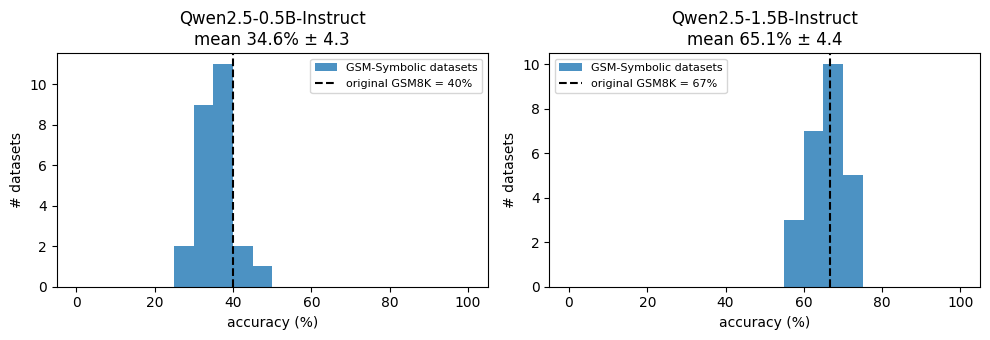

In [15]:
def per_dataset(df):
    return df.groupby("dataset").correct.mean()

models = res.model.unique()
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 3.5), squeeze=False)
for ax, m in zip(axes[0], models):
    r = res[(res.model == m) & (res.exp == "E1")]
    acc = per_dataset(r[r.cond == "both"]) * 100
    orig = r[r.cond == "original"].correct.mean() * 100
    ax.hist(acc, bins=np.arange(0, 105, 5), alpha=.8, color="tab:blue", label="GSM-Symbolic datasets")
    ax.axvline(orig, ls="--", c="k", label=f"original GSM8K = {orig:.0f}%")
    ax.set(title=f"{m}\nmean {acc.mean():.1f}% ± {acc.std():.1f}", xlabel="accuracy (%)", ylabel="# datasets")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### E2: Names vs numbers (paper Fig. 4)
The paper's claim: changing **names** barely matters, while changing **numbers** causes larger drops and more variance.

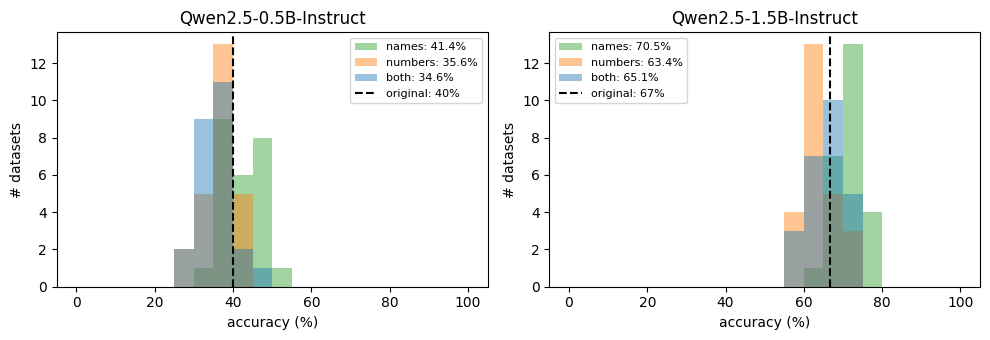

In [16]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 3.5), squeeze=False)
for ax, m in zip(axes[0], models):
    r = res[(res.model == m) & (res.exp.isin(["E1", "E2"]))]
    orig = r[r.cond == "original"].correct.mean() * 100
    for cond, c in [("names", "tab:green"), ("numbers", "tab:orange"), ("both", "tab:blue")]:
        acc = per_dataset(r[r.cond == cond]) * 100
        ax.hist(acc, bins=np.arange(0, 105, 5), alpha=.45, color=c, label=f"{cond}: {acc.mean():.1f}%")
    ax.axvline(orig, ls="--", c="k", label=f"original: {orig:.0f}%")
    ax.set(title=m, xlabel="accuracy (%)", ylabel="# datasets"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### E3: Difficulty (paper Fig. 6)
Adding clauses (P1 = +1, P2 = +2) should lower the mean and **widen** the distribution.

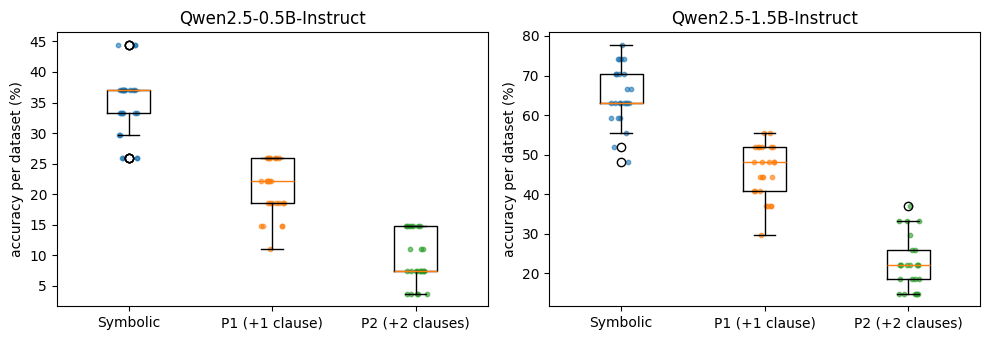

In [17]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 3.5), squeeze=False)
for ax, m in zip(axes[0], models):
    r = res[(res.model == m) & (res.exp == "E3")]
    data = [per_dataset(r[r.cond == c]) * 100 for c in ["symbolic", "p1", "p2"]]
    ax.boxplot(data)
    ax.set_xticks([1, 2, 3], ["Symbolic", "P1 (+1 clause)", "P2 (+2 clauses)"])
    for i, d in enumerate(data, 1):
        ax.scatter(np.full(len(d), i) + np.random.uniform(-.08, .08, len(d)), d, s=10, alpha=.6)
    ax.set(title=m, ylabel="accuracy per dataset (%)")
plt.tight_layout(); plt.show()

### E4: GSM-NoOp (paper Fig. 8)
The questions are paired: identical numbers, with and without the irrelevant sentence.

cond,both,noop,drop (pts)
model,,,
Qwen2.5-0.5B-Instruct,46.0,18.0,28.0
Qwen2.5-1.5B-Instruct,85.1,31.7,53.4


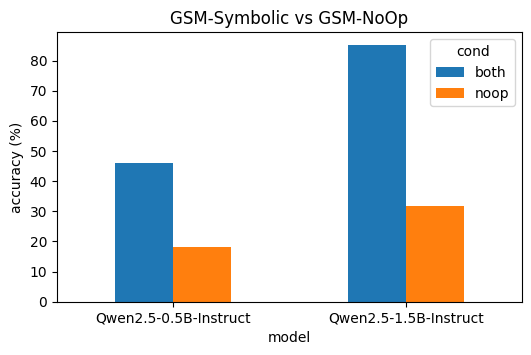

Q: A fog bank rolls in from the ocean to cover a city. It takes 342 minutes to cover every 24 miles of the city. The fog is 4 times thicker than it was last week. If the city is 48 miles across from the oceanfront to the opposite inland edge, how many minutes will it take for the fog bank to cover the whole city? 
GOLD: 684.0 | PRED: 4.0 

MODEL: First, we need to find out how thick the fog is this time around the city. Since it takes 342 minutes to cover every 24 miles, it means the fog covers 342/24 = 14.25 miles per minute. This means the fog is 14.25 miles thick. Now, if the fog is 4 times thicker than it was last week, it would be 14.25 * 4 = 57 miles thick. We know the city is 48 miles across from the oceanfront to the opposite inland edge. So, the fog bank needs to cover 57 miles of the city. To calculate the time it will take, we divide the distance by the thickness of the fog: 57 / 14.25 = 4 minutes. The final answer is 4.


In [18]:
e4 = res[res.exp == "E4"].pivot_table(index=["model", "template", "dataset"], columns="cond", values="correct").reset_index()
summary = e4.groupby("model")[["both", "noop"]].mean() * 100
summary["drop (pts)"] = summary["both"] - summary["noop"]
display(summary.round(1))
summary[["both", "noop"]].plot.bar(rot=0, figsize=(6, 3.5), ylabel="accuracy (%)", title="GSM-Symbolic vs GSM-NoOp")
plt.show()

# Typical failure: the model "uses" the irrelevant number
fails = res[(res.exp == "E4") & (res.cond == "noop") & ~res.correct]
if len(fails):
    f = fails.iloc[0]
    print("Q:", f.question, "\nGOLD:", f.answer, "| PRED:", f.pred, "\n\nMODEL:", f.response[:800])

## 9. Statistical sanity checks: is the evidence as strong as it looks?
A 2026 follow-up, *"The Importance of Being Statistically Earnest: A Critical Re-evaluation of GSM-Symbolic"* (Długosz, Oliveira, Díaz-Rodríguez), argues that several conclusions rest on weak statistics:
- **Variance.** Spread across datasets of only ~100 questions is partly just sampling noise.
- **Significance.** With per-question random effects (GLMMs), only 8 of 20 models showed significant drops.
- **Confound.** GSM-Symbolic integers are **larger** than GSM8K's (KS = 0.12, p < 0.001), so a "drop" may partly be an arithmetic effect rather than a reasoning failure.

We run lightweight versions of these three checks on our own results.

In [19]:
# 9.1  How much of the variance is just binomial noise?
# If every template t has a fixed success rate p_t, a dataset of T questions has
# Var(acc) = sum_t p_t (1 - p_t) / T^2.  Compare that with the observed spread.
rows = []
for m in models:
    r = res[(res.model == m) & (res.exp == "E1") & (res.cond == "both")]
    p_t = r.groupby("template").correct.mean()
    expected_sd = np.sqrt((p_t * (1 - p_t)).sum()) / len(p_t)
    rows.append({"model": m, "observed sd (pts)": per_dataset(r).std() * 100,
                 "noise-only sd (pts)": expected_sd * 100})
pd.DataFrame(rows).round(2)

,model,observed sd (pts),noise-only sd (pts)
0,Qwen2.5-0.5B-Instruct,4.26,3.96
1,Qwen2.5-1.5B-Instruct,4.35,4.82


If the two columns are close, the spread across datasets is **what you would expect from sampling**. It shows that a single benchmark number is uncertain, not necessarily that the model's reasoning is fragile.

In [20]:
# 9.2  Is the original -> symbolic drop significant?  Cluster bootstrap over templates
# (resample whole templates, which respects per-question correlation, like a random effect)
def cluster_bootstrap_drop(r, n_boot=2000, seed=0):
    g = np.random.default_rng(seed)
    orig = r[r.cond == "original"].set_index("template").correct.astype(float)
    sym = r[r.cond == "both"].groupby("template").correct.mean()
    tids = orig.index.intersection(sym.index).to_numpy()
    diff = (orig[tids] - sym[tids]).to_numpy()
    boots = [diff[g.integers(0, len(diff), len(diff))].mean() for _ in range(n_boot)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return diff.mean() * 100, lo * 100, hi * 100

rows = []
for m in models:
    d, lo, hi = cluster_bootstrap_drop(res[(res.model == m) & (res.exp == "E1")])
    rows.append({"model": m, "drop (pts)": d, "95% CI low": lo, "95% CI high": hi,
                 "significant?": not (lo <= 0 <= hi)})
pd.DataFrame(rows).round(1)

,model,drop (pts),95% CI low,95% CI high,significant?
0,Qwen2.5-0.5B-Instruct,5.4,-3.2,14.7,False
1,Qwen2.5-1.5B-Instruct,1.5,-8.3,10.9,False


median integer  original=12  symbolic=17   KS=0.120  p=0.00888


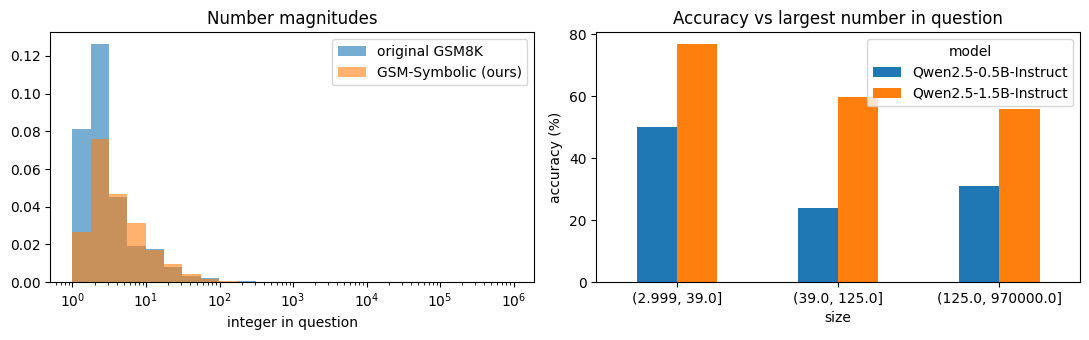

In [21]:
# 9.3  The number-magnitude confound
from scipy.stats import ks_2samp

def ints_in(texts):
    return [int(x.replace(",", "")) for t in texts for x in re.findall(r"(?<![\d.])\d[\d,]*(?![\d.]*\d)", t)]

e1 = bench[bench.exp == "E1"]
orig_n, sym_n = ints_in(e1[e1.cond == "original"].question), ints_in(e1[e1.cond == "both"].question)
ks = ks_2samp(orig_n, sym_n)
print(f"median integer  original={np.median(orig_n):.0f}  symbolic={np.median(sym_n):.0f}   "
      f"KS={ks.statistic:.3f}  p={ks.pvalue:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.logspace(0, np.log10(max(orig_n + sym_n) + 1), 25)
axes[0].hist(orig_n, bins=bins, alpha=.6, density=True, label="original GSM8K")
axes[0].hist(sym_n, bins=bins, alpha=.6, density=True, label="GSM-Symbolic (ours)")
axes[0].set(xscale="log", xlabel="integer in question", title="Number magnitudes"); axes[0].legend()

# Does accuracy fall with the size of the largest number in a question?
sym = res[(res.exp.isin(["E1", "E2"])) & (res.cond.isin(["both", "numbers"]))].copy()
sym["max_int"] = sym.question.map(lambda q: max(ints_in([q]) or [0]))
sym["size"] = pd.qcut(sym.max_int, 3, duplicates="drop")   # terciles of the largest number
(sym.groupby(["size", "model"], observed=True).correct.mean().unstack() * 100).plot.bar(
    ax=axes[1], rot=0, ylabel="accuracy (%)", title="Accuracy vs largest number in question")
plt.tight_layout(); plt.show()

## 10. Takeaways (QUICK = False: 60 templates × 25 datasets for E1/E2, 27 × 25 for E3, 14 × 25 for E4)

| | Qwen2.5-0.5B | Qwen2.5-1.5B | Paper's claim | Reproduced? |
|---|---|---|---|---|
| **E1** original → symbolic | 40.0 → 34.6 ± 4.3 | 66.7 → 65.1 ± 4.4 | symbolic below original, wide spread | direction yes, but **not significant** (§9.2) |
| **E2** names / numbers | 41.4 / 35.6 | 70.5 / 63.4 | numbers hurt more than names | **yes** (≈6–7 pts gap) |
| **E3** Symbolic → P1 → P2 | 34.7 → 20.6 → 9.2 | 65.0 → 45.6 → 22.4 | accuracy falls with each clause | **yes, strongly** |
| **E4** base → NoOp | 46.0 → 18.0 | 85.1 → 31.7 | large drop from irrelevant clauses | **yes, strongest effect** (−28 / −53 pts) |

- **E1:** Both models score slightly lower on symbolic variants than on the original questions. However, the cluster-bootstrap 95% CIs of the drop include 0 (0.5B: 5.4 [−3.2, 14.7]; 1.5B: 1.5 [−8.3, 10.9]). At this scale we **cannot** claim that the models are worse on GSM-Symbolic than on GSM8K.
- **E2:** Changing only names barely hurts (it even helps the 1.5B model a little). Changing numbers costs about 6–7 points for both models. This matches the paper's ordering.
- **E3:** This is the clearest difficulty result. Two extra clauses leave only about 27% (0.5B) and 34% (1.5B) of the Symbolic accuracy. The bigger model is more accurate but only slightly more robust in relative terms. Each extra step is another chance to make an error.
- **E4:** Adding one irrelevant sentence costs the 1.5B model 53 points. The design is paired (same question with and without the NoOp), so this is not sampling noise. The failure in §8 shows the mechanism the paper describes: the model turns "4 times thicker" into a multiplication. The base accuracy (85%) is higher than in E1 because our 14 NoOp templates are an easier subset. The drop is still measured within the same templates.
- **§9.1 (variance):** The spread across datasets is **almost exactly binomial noise**: observed SD 4.3 / 4.4 pts versus noise-only 4.0 / 4.8 pts. The paper's "high variance across instantiations" is largely what you would expect from a 60-question test whose questions have fixed difficulties. It is not, by itself, evidence of fragile reasoning.
- **§9.3 (confound):** Our sampled numbers are larger than GSM8K's (median 17 vs 12, KS p = 0.009), and accuracy falls as the largest number in a question grows (1.5B: 77% → 60% → 56% across terciles). Part of the "numbers" effect in E1/E2 may therefore come from **harder arithmetic** rather than memorization. The tercile split mixes templates, so a within-template analysis would be needed to separate the two explanations.

**Bottom line:** The results that hold up are the ones with paired comparisons and large effects: P1/P2 difficulty scaling and GSM-NoOp. The headline claim that "accuracy drops and varies on symbolic variants" does not survive basic statistics at this scale. This matches the 2026 critique: the variance is mostly sampling noise, and the number changes are confounded with difficulty.

**Limitations of this reproduction:** we use a different name/vocabulary pool, our own NoOp sentences, small 0.5B/1.5B models, and fewer templates and datasets than the paper (100 × 50). The "original" condition has only 60 questions, so its accuracy has an SE of about 6 pts. A smaller QUICK=True run (20 × 8) gives the same qualitative picture.
